# Mathematical Foundations and Python Implementation of Transformers
## M.Tech Deep Learning / Natural Language Processing Assignment

**Programming language:** Python 3  
**Implementation:** NumPy only for Transformer operations; Matplotlib for visualizations  
**Coverage:** Questions 1–10 (100 marks)

### Important assignment requirements
- Implement positional encoding, attention, masking, and Transformer blocks from scratch.
- Do not use PyTorch, TensorFlow, Keras, JAX, or prebuilt attention layers.
- Show intermediate matrices, tensor dimensions, verification tests, and visualizations.
- Use the mathematical definitions and task requirements in the supplied assignment.

> Run the notebook from top to bottom. All random experiments use fixed seeds where appropriate so results are reproducible.

## 0. Setup and common utilities

The notebook uses NumPy for numerical computation and Matplotlib for plots. The helper functions below are small utilities for displaying shapes and checking numerical results; they do not implement Transformer layers.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

np.set_printoptions(precision=6, suppress=True)
SEED = 42
rng = np.random.default_rng(SEED)

print("NumPy version:", np.__version__)

NumPy version: 2.4.6


# Question 1. Sinusoidal Positional Encoding (10 Marks)

## 1.1 Mathematical definition

For position `pos`, dimension-pair index `i`, and model dimension `d_model`:

\[
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]
\[
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

Even dimensions use sine and odd dimensions use cosine. The frequency for pair `i` is
\(\omega_i=10000^{-2i/d_{model}}\). As `i` increases, frequency decreases.

## 1.2 NumPy implementation

In [ ]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return positional encoding with shape (seq_len, d_model)."""
    if seq_len <= 0 or d_model <= 0:
        raise ValueError("seq_len and d_model must be positive")

    positions = np.arange(seq_len, dtype=np.float64)[:, None]
    even_dimensions = np.arange(0, d_model, 2, dtype=np.float64)

    div_term = np.exp(
        even_dimensions * (-np.log(10000.0) / d_model)
    )

    pe = np.zeros((seq_len, d_model), dtype=np.float64)
    pe[:, 0::2] = np.sin(positions * div_term)

    # Handles both even and odd model dimensions.
    odd_count = pe[:, 1::2].shape[1]
    pe[:, 1::2] = np.cos(positions * div_term[:odd_count])
    return pe


# Required assignment experiment: seq_len=20, d_model=16
seq_len, d_model = 20, 16
PE = sinusoidal_positional_encoding(seq_len, d_model)

print("Positional encoding shape:", PE.shape)
print("First five rows:\n", PE[:5])
assert PE.shape == (20, 16)

Positional encoding shape: (20, 16)
First five rows:
 [[ 0.        1.        0.        1.        0.        1.        0.
   1.        0.        1.        0.        1.        0.        1.
   0.        1.      ]
 [ 0.841471  0.540302  0.310984  0.950415  0.099833  0.995004  0.031618
   0.9995    0.01      0.99995   0.003162  0.999995  0.001     1.
   0.000316  1.      ]
 [ 0.909297 -0.416147  0.591127  0.806578  0.198669  0.980067  0.063203
   0.998001  0.019999  0.9998    0.006325  0.99998   0.002     0.999998
   0.000632  1.      ]
 [ 0.14112  -0.989992  0.812649  0.582754  0.29552   0.955336  0.094726
   0.995503  0.029996  0.99955   0.009487  0.999955  0.003     0.999996
   0.000949  1.      ]
 [-0.756802 -0.653644  0.953581  0.301137  0.389418  0.921061  0.126154
   0.992011  0.039989  0.9992    0.012649  0.99992   0.004     0.999992
   0.001265  0.999999]]


## 1.3 Manual-calculation verification: d_model=4, positions 0, 1, 2

For `d_model=4`, the two dimension-pair denominators are:
- `i=0`: \(10000^{0}=1\)
- `i=1`: \(10000^{1/2}=100\)

Thus each row is `[sin(pos), cos(pos), sin(pos/100), cos(pos/100)]`.

In [ ]:
PE_manual_case = sinusoidal_positional_encoding(seq_len=3, d_model=4)
print("3 x 4 positional encoding matrix:")
print(PE_manual_case)

expected = np.array([
    [0.0,       1.0,        0.0,       1.0],
    [np.sin(1), np.cos(1),  np.sin(.01), np.cos(.01)],
    [np.sin(2), np.cos(2), np.sin(.02), np.cos(.02)]
])
print("\nMaximum absolute difference:", np.max(np.abs(PE_manual_case - expected)))
assert np.allclose(PE_manual_case, expected, atol=1e-12)

3 x 4 positional encoding matrix:
[[ 0.        1.        0.        1.      ]
 [ 0.841471  0.540302  0.01      0.99995 ]
 [ 0.909297 -0.416147  0.019999  0.9998  ]]

Maximum absolute difference: 1.0408340855860843e-17


## 1.4 Visualization of the required 20 × 16 encoding matrix

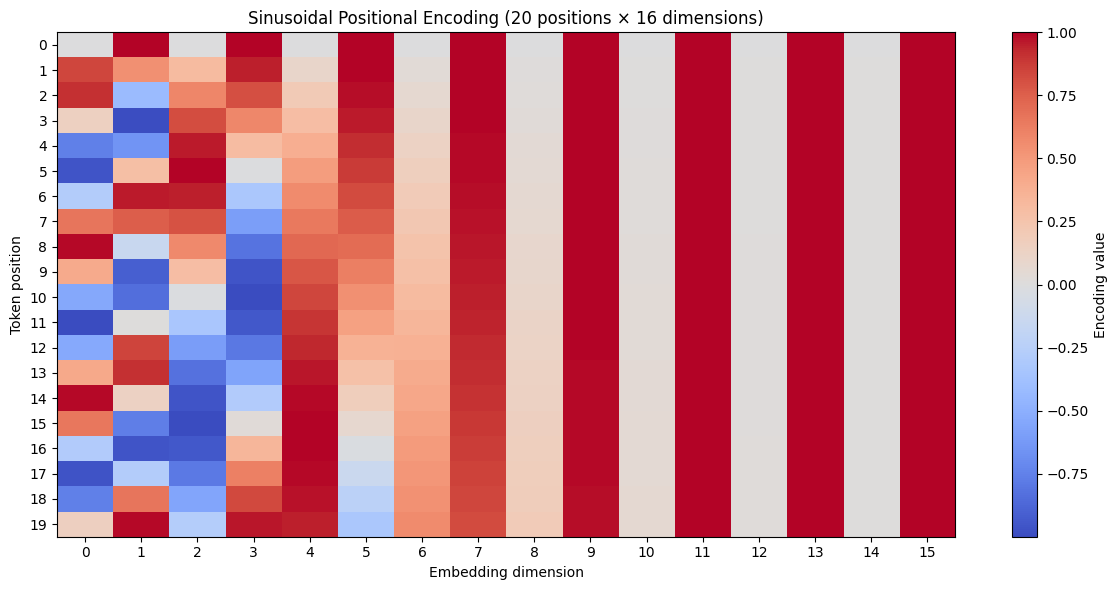

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(PE, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Encoding value")
plt.xlabel("Embedding dimension")
plt.ylabel("Token position")
plt.title("Sinusoidal Positional Encoding (20 positions × 16 dimensions)")
plt.xticks(range(d_model))
plt.yticks(range(seq_len))
plt.tight_layout()
plt.show()

## 1.5 Interpretation

Sine and cosine are periodic functions. For dimension-pair frequency \(\omega_i\), the period is \(T_i=2\pi/\omega_i\). Higher-frequency dimensions change rapidly with position; lower-frequency dimensions change slowly. The collection of frequencies gives each position a distinctive pattern and provides the model with information about token order and relative offsets.

# Question 2. Scaled Dot-Product Self-Attention from Scratch (12 Marks)

The attention equation is:

\[
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

If there are `n` tokens, then `Q` and `K` have shape `(n, d_k)`, the score/weight matrix has shape `(n, n)`, and `V` has shape `(n, d_v)`.

In [ ]:
def softmax(x, axis=-1):
    """Numerically stable softmax implemented with NumPy."""
    x = np.asarray(x, dtype=np.float64)
    shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


def scaled_dot_product_attention(Q, K, V):
    """
    Q: (n_queries, d_k)
    K: (n_keys, d_k)
    V: (n_keys, d_v)
    Returns output (n_queries, d_v) and weights (n_queries, n_keys).
    """
    Q, K, V = map(lambda a: np.asarray(a, dtype=np.float64), (Q, K, V))
    if Q.ndim != 2 or K.ndim != 2 or V.ndim != 2:
        raise ValueError("Q, K and V must be 2-D arrays")
    if Q.shape[1] != K.shape[1] or K.shape[0] != V.shape[0]:
        raise ValueError("Incompatible Q, K, V dimensions")

    scores = (Q @ K.T) / np.sqrt(K.shape[1])
    weights = softmax(scores, axis=-1)
    output = weights @ V
    return output, weights


# Required manual example: Q=K=V=identity matrix
Q2 = np.array([[1., 0.],
               [0., 1.]])
K2 = Q2.copy()
V2 = Q2.copy()

raw_scores = Q2 @ K2.T
scaled_scores = raw_scores / np.sqrt(2)
weights2 = softmax(scaled_scores, axis=1)
output2, returned_weights2 = scaled_dot_product_attention(Q2, K2, V2)

print("QK^T:\n", raw_scores)
print("\nScaled scores:\n", scaled_scores)
print("\nRow-wise softmax weights:\n", weights2)
print("\nAttention output:\n", output2)
print("\nRow sums:", returned_weights2.sum(axis=1))

assert np.allclose(returned_weights2.sum(axis=1), 1.0)
assert np.allclose(output2, weights2 @ V2)

QK^T:
 [[1. 0.]
 [0. 1.]]

Scaled scores:
 [[0.707107 0.      ]
 [0.       0.707107]]

Row-wise softmax weights:
 [[0.669762 0.330238]
 [0.330238 0.669762]]

Attention output:
 [[0.669762 0.330238]
 [0.330238 0.669762]]

Row sums: [1. 1.]


## 2.1 Verification

Every attention-weight row must sum to one because softmax normalizes each query's scores across all keys. The Python output above can be compared directly with the handwritten calculation.

# Question 3. Learnable Query, Key, and Value Projections (10 Marks)

Given an input matrix \(X\in\mathbb{R}^{n\times d_{model}}\):

\[
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
\]

For a common model dimension, each projection matrix can be `(d_model, d_model)`. In general, the output widths can differ, provided Q and K have the same feature width and K and V have the same number of token rows.

In [ ]:
def self_attention(X, W_Q, W_K, W_V):
    """Project X into Q, K, V and perform scaled dot-product attention."""
    Q = np.asarray(X) @ np.asarray(W_Q)
    K = np.asarray(X) @ np.asarray(W_K)
    V = np.asarray(X) @ np.asarray(W_V)
    output, weights = scaled_dot_product_attention(Q, K, V)
    return output, weights, Q, K, V


X3 = np.array([[1., 2.],
               [0., 1.]])
WQ3 = np.array([[1., 0.],
                [0., 1.]])
WK3 = np.array([[0., 1.],
                [1., 0.]])
WV3 = np.array([[2., 0.],
                [0., 1.]])

out3, weights3, Q3, K3, V3 = self_attention(X3, WQ3, WK3, WV3)

print("Q = XW_Q:\n", Q3)
print("\nK = XW_K:\n", K3)
print("\nV = XW_V:\n", V3)
print("\nScaled attention weights:\n", weights3)
print("\nAttention output:\n", out3)

# Identity-projection comparison
I2 = np.eye(2)
identity_out, identity_weights, *_ = self_attention(X3, I2, I2, I2)
print("\nIdentity-projection weights:\n", identity_weights)
print("\nIdentity-projection output:\n", identity_out)

Q = XW_Q:
 [[1. 2.]
 [0. 1.]]

K = XW_K:
 [[2. 1.]
 [1. 0.]]

V = XW_V:
 [[2. 2.]
 [0. 1.]]

Scaled attention weights:
 [[0.892958 0.107042]
 [0.669762 0.330238]]

Attention output:
 [[1.785916 1.892958]
 [1.339523 1.669762]]

Identity-projection weights:
 [[0.892958 0.107042]
 [0.669762 0.330238]]

Identity-projection output:
 [[0.892958 1.892958]
 [0.669762 1.669762]]


## 3.1 Analysis

The projections learn which aspects of each token should be used as a query, key, or value. Changing the projection matrices changes dot-product similarities and therefore changes the attention distribution. Identity projections pass the original feature coordinates through unchanged; learned projections can rotate, scale, or combine features to create useful relationships.

# Question 4. Causal Self-Attention and Masking (10 Marks)

Causal masking prevents a token from attending to future tokens. The assignment defines:

\[
M_{ij}=0\;\text{if }j\leq i,\qquad M_{ij}=-\infty\;\text{if }j>i
\]

The 4 × 4 additive mask is:

In [ ]:
causal_mask_4 = np.triu(np.full((4, 4), -np.inf), k=1)
print(causal_mask_4)

[[  0. -inf -inf -inf]
 [  0.   0. -inf -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0.   0.]]


## 4.1 Causal attention implementation

The function below builds the upper-triangular future-token mask directly with NumPy. `-inf` ensures that masked entries receive zero probability after softmax.

In [ ]:
def causal_self_attention(Q, K, V):
    """Causally masked scaled dot-product attention."""
    Q, K, V = map(lambda a: np.asarray(a, dtype=np.float64), (Q, K, V))
    if Q.shape[0] != K.shape[0]:
        raise ValueError("For causal self-attention, Q and K lengths must match")
    scores = (Q @ K.T) / np.sqrt(K.shape[1])
    future_mask = np.triu(np.ones(scores.shape, dtype=bool), k=1)
    scores = np.where(future_mask, -np.inf, scores)
    weights = softmax(scores, axis=-1)
    return weights @ V, weights, scores


Q4 = np.array([[1., 0.],
               [0., 1.],
               [1., 1.]])
K4 = Q4.copy()
V4 = Q4.copy()

out4, weights4, masked_scores4 = causal_self_attention(Q4, K4, V4)
print("Unmasked scaled scores:\n", (Q4 @ K4.T) / np.sqrt(2))
print("\nMasked scores:\n", masked_scores4)
print("\nCausal attention weights:\n", weights4)
print("\nCausal attention output:\n", out4)

# All future-token weights must be exactly zero.
future_positions = np.triu(np.ones(weights4.shape, dtype=bool), k=1)
print("\nFuture-token weights:", weights4[future_positions])
assert np.all(weights4[future_positions] == 0.0)
assert np.allclose(weights4.sum(axis=1), 1.0)

Unmasked scaled scores:
 [[0.707107 0.       0.707107]
 [0.       0.707107 0.707107]
 [0.707107 0.707107 1.414214]]

Masked scores:
 [[0.707107     -inf     -inf]
 [0.       0.707107     -inf]
 [0.707107 0.707107 1.414214]]

Causal attention weights:
 [[1.       0.       0.      ]
 [0.330238 0.669762 0.      ]
 [0.248255 0.248255 0.50349 ]]

Causal attention output:
 [[1.       0.      ]
 [0.330238 0.669762]
 [0.751745 0.751745]]

Future-token weights: [0. 0. 0.]


## 4.2 Padding mask versus causal mask

- **Causal mask:** blocks attention to later positions, preserving autoregressive generation.
- **Padding mask:** blocks positions that represent padding rather than real tokens. It can be applied to key positions regardless of whether they are earlier or later.

A causal mask is triangular; a padding mask depends on which sequence positions are padding.

# Question 5. Cross-Attention in Encoder–Decoder Transformers (10 Marks)

In cross-attention, decoder states provide queries while encoder states provide keys and values:

\[
Q=H_{decoder}W_Q,\quad K=H_{encoder}W_K,\quad V=H_{encoder}W_V
\]

For `n` decoder tokens and `m` encoder tokens, the attention-weight matrix has shape `(n, m)`, not necessarily a square matrix.

In [ ]:
def cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V):
    """Decoder-to-encoder cross-attention; returns output and weights."""
    Q = np.asarray(decoder_states) @ np.asarray(W_Q)
    K = np.asarray(encoder_states) @ np.asarray(W_K)
    V = np.asarray(encoder_states) @ np.asarray(W_V)
    output, weights = scaled_dot_product_attention(Q, K, V)
    return output, weights, Q, K, V


# Assignment's manual example: one decoder query, three encoder keys/values
Q5 = np.array([[1., 0.]])
K5 = np.array([[1., 0.],
               [0., 1.],
               [1., 1.]])
V5 = np.array([[2., 0.],
               [0., 2.],
               [1., 1.]])

scores5 = (Q5 @ K5.T) / np.sqrt(2)
weights5 = softmax(scores5, axis=1)
output5 = weights5 @ V5

print("Scaled scores (shape 1 x 3):", scores5)
print("Softmax weights:", weights5)
print("Output:", output5)

# Function test: the function derives V from encoder_states.
# The separate manual calculation above uses the assignment's supplied V5.
out5_fn, w5_fn, *_ = cross_attention(
    Q5, K5, np.eye(2), np.eye(2), np.eye(2)
)
expected_fn_out, expected_fn_weights = scaled_dot_product_attention(Q5, K5, K5)
assert np.allclose(out5_fn, expected_fn_out)
assert np.allclose(w5_fn, expected_fn_weights)
assert w5_fn.shape == (1, 3)

Scaled scores (shape 1 x 3): [[0.707107 0.       0.707107]]
Softmax weights: [[0.401112 0.197776 0.401112]]
Output: [[1.203336 0.796664]]


## 5.1 Interpretation

Cross-attention retrieves source information relevant to each decoder position. Since the decoder and encoder sequences can have different lengths, the attention matrix has `n` rows (decoder queries) and `m` columns (encoder keys); it need not be square.

# Question 6. Multi-Head Attention: Parallel Attention Subspaces (12 Marks)

For `H` heads, each head performs attention in its own projected subspace. The head outputs are concatenated and multiplied by an output projection:

\[
head_h=Attention(XW_Q^{(h)},XW_K^{(h)},XW_V^{(h)})
\]
\[
MultiHead(X)=Concat(head_1,\ldots,head_H)W_O
\]

For the assignment's dimension example, `d_model=8`, `H=2`, and `d_k=d_v=4`. Each head output has shape `(seq_len, 4)`; concatenation restores `(seq_len, 8)`.

## 6.1 General multi-head attention implementation

This implementation supports both self-attention and cross-attention. Projection matrices have shape `(d_model, d_model)` and the projected features are split evenly across heads. An optional boolean mask uses `True` to mean “block this query-key pair.”

In [ ]:
def multi_head_attention(X_query, W_Q, W_K, W_V, W_O, num_heads,
                         X_key_value=None, mask=None):
    """
    Multi-head attention using NumPy only.

    X_query:     (n_query, d_model)
    X_key_value: (n_key, d_model); defaults to X_query (self-attention)
    W_Q/W_K/W_V/W_O: each (d_model, d_model)
    mask: optional boolean array broadcastable to (n_query, n_key);
          True means the attention connection is blocked.
    Returns:
      output:  (n_query, d_model)
      weights: (num_heads, n_query, n_key)
    """
    X_query = np.asarray(X_query, dtype=np.float64)
    if X_key_value is None:
        X_key_value = X_query
    X_key_value = np.asarray(X_key_value, dtype=np.float64)

    d_model = X_query.shape[1]
    if d_model % num_heads != 0:
        raise ValueError("d_model must be divisible by num_heads")
    if X_key_value.shape[1] != d_model:
        raise ValueError("Query and key/value model dimensions must match")

    Q_all = X_query @ W_Q
    K_all = X_key_value @ W_K
    V_all = X_key_value @ W_V

    d_head = d_model // num_heads
    head_outputs = []
    all_weights = []

    for h in range(num_heads):
        start, end = h * d_head, (h + 1) * d_head
        Qh = Q_all[:, start:end]
        Kh = K_all[:, start:end]
        Vh = V_all[:, start:end]

        scores = (Qh @ Kh.T) / np.sqrt(d_head)
        if mask is not None:
            scores = np.where(mask, -np.inf, scores)
        weights = softmax(scores, axis=-1)
        head_outputs.append(weights @ Vh)
        all_weights.append(weights)

    concatenated = np.concatenate(head_outputs, axis=-1)
    output = concatenated @ W_O
    return output, np.stack(all_weights, axis=0)


# Assignment shape experiment: d_model=8, H=2
rng6 = np.random.default_rng(6)
X6 = rng6.normal(size=(5, 8))
WQ6 = rng6.normal(scale=0.2, size=(8, 8))
WK6 = rng6.normal(scale=0.2, size=(8, 8))
WV6 = rng6.normal(scale=0.2, size=(8, 8))
WO6 = rng6.normal(scale=0.2, size=(8, 8))

out6, weights6 = multi_head_attention(X6, WQ6, WK6, WV6, WO6, num_heads=2)
print("Input shape:", X6.shape)
print("Output shape:", out6.shape)
print("Attention weights shape:", weights6.shape)
print("Per-head row sums (should be 1):\n", weights6.sum(axis=-1))
assert out6.shape == (5, 8)
assert weights6.shape == (2, 5, 5)
assert np.allclose(weights6.sum(axis=-1), 1.0)

Input shape: (5, 8)
Output shape: (5, 8)
Attention weights shape: (2, 5, 5)
Per-head row sums (should be 1):
 [[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]


## 6.2 Handwritten two-head example from the assignment

Use `X=I₂`. Head 1 uses identity Q/K/V projections. Head 2 uses the coordinate-swap matrix for Q and K, and identity for V. No output projection is required for this manual example.

In [ ]:
X6_manual = np.eye(2)
I = np.eye(2)
SWAP = np.array([[0., 1.],
                 [1., 0.]])

head1_out, head1_weights = scaled_dot_product_attention(
    X6_manual @ I, X6_manual @ I, X6_manual @ I
)
head2_out, head2_weights = scaled_dot_product_attention(
    X6_manual @ SWAP, X6_manual @ SWAP, X6_manual @ I
)
manual_concat = np.concatenate([head1_out, head2_out], axis=1)

print("Head 1 weights:\n", head1_weights)
print("Head 1 output:\n", head1_out)
print("\nHead 2 weights:\n", head2_weights)
print("Head 2 output:\n", head2_out)
print("\nConcatenated output (no W_O):\n", manual_concat)

Head 1 weights:
 [[0.669762 0.330238]
 [0.330238 0.669762]]
Head 1 output:
 [[0.669762 0.330238]
 [0.330238 0.669762]]

Head 2 weights:
 [[0.669762 0.330238]
 [0.330238 0.669762]]
Head 2 output:
 [[0.669762 0.330238]
 [0.330238 0.669762]]

Concatenated output (no W_O):
 [[0.669762 0.330238 0.669762 0.330238]
 [0.330238 0.669762 0.330238 0.669762]]


## 6.3 Analysis

Different heads can learn different token relationships or feature subspaces. More heads do not automatically improve performance: with a fixed model dimension, increasing the number of heads reduces the width allocated to each head, and extra heads add computation and parameters without guaranteeing useful specialization.

# Question 7. Numerical Stability and Attention Temperature (8 Marks)

## 7.1 Why subtracting the maximum does not change softmax

For any constant `c`:

\[
softmax(z_i-c)=\frac{e^{z_i-c}}{\sum_j e^{z_j-c}}
=\frac{e^{-c}e^{z_i}}{e^{-c}\sum_j e^{z_j}}
=softmax(z_i)
\]

Choosing `c=max(z)` prevents unnecessarily large exponentials and improves numerical stability.

In [ ]:
def stable_softmax(x, axis=-1):
    """Numerically stable softmax, subtracting the maximum per axis."""
    x = np.asarray(x, dtype=np.float64)
    shifted = x - np.max(x, axis=axis, keepdims=True)
    ex = np.exp(shifted)
    return ex / np.sum(ex, axis=axis, keepdims=True)


test_logits = np.array([1000., 1001., 1002.])
print("Stable softmax:", stable_softmax(test_logits))
print("Stable result is finite:", np.all(np.isfinite(stable_softmax(test_logits))))

with np.errstate(over="ignore", invalid="ignore"):
    direct = np.exp(test_logits) / np.sum(np.exp(test_logits))
print("Direct exponentiation:", direct)
print("Direct result finite:", np.all(np.isfinite(direct)))
assert np.all(np.isfinite(stable_softmax(test_logits)))

Stable softmax: [0.090031 0.244728 0.665241]
Stable result is finite: True
Direct exponentiation: [nan nan nan]
Direct result finite: False


## 7.2 Temperature experiment

The assignment asks for attention weights using \(QK^T/T\) for `T ∈ {0.5, 1, 2, 4}`. A lower temperature makes the distribution sharper; a higher temperature makes it more uniform.

Temperature 0.5:
[[0.880797 0.119203]
 [0.119203 0.880797]]
Temperature 1:
[[0.731059 0.268941]
 [0.268941 0.731059]]
Temperature 2:
[[0.622459 0.377541]
 [0.377541 0.622459]]
Temperature 4:
[[0.562177 0.437823]
 [0.437823 0.562177]]


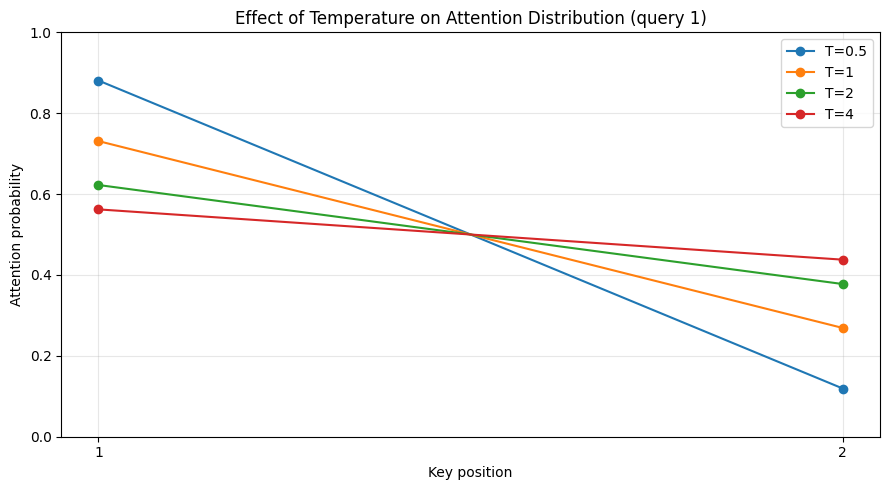

In [ ]:
Q7 = np.array([[1., 0.],
               [0., 1.]])
K7 = Q7.copy()
base_scores7 = Q7 @ K7.T
temperatures = [0.5, 1, 2, 4]
temperature_weights = {}

for T in temperatures:
    temperature_weights[T] = stable_softmax(base_scores7 / T, axis=-1)
    print(f"Temperature {T}:\n{temperature_weights[T]}")

plt.figure(figsize=(9, 5))
for T in temperatures:
    plt.plot(
        np.arange(1, 3),
        temperature_weights[T][0],
        marker="o",
        label=f"T={T}"
    )
plt.xlabel("Key position")
plt.ylabel("Attention probability")
plt.title("Effect of Temperature on Attention Distribution (query 1)")
plt.xticks([1, 2])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 7.3 Interpretation: scaling and gradients

Dividing scores by a larger temperature reduces their magnitude and usually makes softmax probabilities more uniform. Smaller temperatures amplify score differences and make attention sharper. The original Transformer divides by \(\sqrt{d_k}\) because dot products tend to grow in magnitude as key dimension increases; scaling helps keep softmax inputs in a range with useful gradients rather than saturated probabilities.

# Question 8. Transformer Encoder Block from Scratch (10 Marks)

The assignment specifies a post-normalization encoder block:

\[
H=LayerNorm(X+MHA(X))
\]
\[
Y=LayerNorm(H+FFN(H))
\]
\[
FFN(H)=ReLU(HW_1+b_1)W_2+b_2
\]

Layer normalization is applied independently to each token across its feature dimension.

In [ ]:
def layer_norm(X, gamma, beta, eps=1e-5):
    """Layer normalization across the last (feature) dimension."""
    X = np.asarray(X, dtype=np.float64)
    mean = np.mean(X, axis=-1, keepdims=True)
    variance = np.var(X, axis=-1, keepdims=True)
    normalized = (X - mean) / np.sqrt(variance + eps)
    return gamma * normalized + beta


def relu(x):
    return np.maximum(0.0, x)


def feed_forward(X, W1, b1, W2, b2):
    """Position-wise two-layer feed-forward network."""
    hidden = relu(X @ W1 + b1)
    return hidden @ W2 + b2


def transformer_encoder_block(X, params):
    """Post-normalization encoder block, without dropout."""
    attn, attn_weights = multi_head_attention(
        X, params["W_Q"], params["W_K"], params["W_V"],
        params["W_O"], params["num_heads"]
    )
    H = layer_norm(X + attn, params["gamma1"], params["beta1"])

    ffn = feed_forward(
        H, params["W1"], params["b1"], params["W2"], params["b2"]
    )
    Y = layer_norm(H + ffn, params["gamma2"], params["beta2"])
    return Y, attn_weights


# Example encoder configuration
rng8 = np.random.default_rng(8)
seq_len8, d_model8, d_ff8, heads8 = 5, 8, 16, 2
X8 = rng8.normal(size=(seq_len8, d_model8))

params8 = {
    "W_Q": rng8.normal(scale=0.15, size=(d_model8, d_model8)),
    "W_K": rng8.normal(scale=0.15, size=(d_model8, d_model8)),
    "W_V": rng8.normal(scale=0.15, size=(d_model8, d_model8)),
    "W_O": rng8.normal(scale=0.15, size=(d_model8, d_model8)),
    "num_heads": heads8,
    "gamma1": np.ones(d_model8), "beta1": np.zeros(d_model8),
    "gamma2": np.ones(d_model8), "beta2": np.zeros(d_model8),
    "W1": rng8.normal(scale=0.15, size=(d_model8, d_ff8)),
    "b1": np.zeros(d_ff8),
    "W2": rng8.normal(scale=0.15, size=(d_ff8, d_model8)),
    "b2": np.zeros(d_model8)
}

Y8, encoder_weights8 = transformer_encoder_block(X8, params8)
print("Encoder input shape:", X8.shape)
print("Encoder attention weights shape:", encoder_weights8.shape)
print("Encoder output shape:", Y8.shape)
assert Y8.shape == (5, 8)

Encoder input shape: (5, 8)
Encoder attention weights shape: (2, 5, 5)
Encoder output shape: (5, 8)


## 8.1 Architecture and interpretation

Flow: input → multi-head self-attention → residual addition → layer normalization → position-wise FFN → residual addition → layer normalization.

- **Attention** mixes information across token positions.
- **FFN** applies the same feature transformation independently to each token.
- **Residual connections** provide direct paths for information and gradients.
- **Layer normalization** stabilizes feature statistics at each token.

# Question 9. Transformer Decoder Block and Complete Architecture (10 Marks)

A decoder block performs:
1. Causally masked decoder self-attention.
2. Residual addition and normalization.
3. Encoder–decoder cross-attention.
4. Residual addition and normalization.
5. Position-wise feed-forward network.
6. Residual addition and normalization.

The decoder uses causal masking so a position cannot access future target tokens. Cross-attention queries come from decoder states; keys and values come from encoder outputs.

In [ ]:
def multi_head_attention_projected(Q_all, K_all, V_all, W_O,
                                   num_heads, mask=None):
    """Multi-head attention when Q/K/V have already been projected."""
    d_model = Q_all.shape[1]
    if d_model % num_heads:
        raise ValueError("Projected dimension must be divisible by num_heads")
    d_head = d_model // num_heads

    outputs, weights_all = [], []
    for h in range(num_heads):
        s, e = h * d_head, (h + 1) * d_head
        Qh, Kh, Vh = Q_all[:, s:e], K_all[:, s:e], V_all[:, s:e]
        scores = (Qh @ Kh.T) / np.sqrt(d_head)
        if mask is not None:
            scores = np.where(mask, -np.inf, scores)
        weights = softmax(scores, axis=-1)
        outputs.append(weights @ Vh)
        weights_all.append(weights)

    concat = np.concatenate(outputs, axis=-1)
    return concat @ W_O, np.stack(weights_all)


def transformer_decoder_block(decoder_input, encoder_output, params):
    """Post-normalization decoder block with causal self- and cross-attention."""
    n_dec = decoder_input.shape[0]
    causal_mask = np.triu(np.ones((n_dec, n_dec), dtype=bool), k=1)

    # 1. Masked decoder self-attention
    self_attn, self_weights = multi_head_attention(
        decoder_input,
        params["W_Q_self"], params["W_K_self"],
        params["W_V_self"], params["W_O_self"],
        params["num_heads"], mask=causal_mask
    )
    H1 = layer_norm(
        decoder_input + self_attn, params["gamma1"], params["beta1"]
    )

    # 2. Cross-attention: decoder queries; encoder keys and values
    cross_attn, cross_weights = multi_head_attention(
        H1,
        params["W_Q_cross"], params["W_K_cross"],
        params["W_V_cross"], params["W_O_cross"],
        params["num_heads"], X_key_value=encoder_output
    )
    H2 = layer_norm(H1 + cross_attn, params["gamma2"], params["beta2"])

    # 3. Position-wise feed-forward network
    ffn = feed_forward(H2, params["W1"], params["b1"], params["W2"], params["b2"])
    Y = layer_norm(H2 + ffn, params["gamma3"], params["beta3"])

    return Y, self_weights, cross_weights


# Required assignment dimensions: d_model=8, 2 heads, encoder length=5,
# decoder length=3.
rng9 = np.random.default_rng(9)
d_model9, heads9, d_ff9 = 8, 2, 16
decoder_input9 = rng9.normal(size=(3, d_model9))
encoder_output9 = rng9.normal(size=(5, d_model9))

def random_projection(rng, d):
    return rng.normal(scale=0.15, size=(d, d))

params9 = {
    "num_heads": heads9,
    "W_Q_self": random_projection(rng9, d_model9),
    "W_K_self": random_projection(rng9, d_model9),
    "W_V_self": random_projection(rng9, d_model9),
    "W_O_self": random_projection(rng9, d_model9),
    "W_Q_cross": random_projection(rng9, d_model9),
    "W_K_cross": random_projection(rng9, d_model9),
    "W_V_cross": random_projection(rng9, d_model9),
    "W_O_cross": random_projection(rng9, d_model9),
    "gamma1": np.ones(d_model9), "beta1": np.zeros(d_model9),
    "gamma2": np.ones(d_model9), "beta2": np.zeros(d_model9),
    "gamma3": np.ones(d_model9), "beta3": np.zeros(d_model9),
    "W1": rng9.normal(scale=0.15, size=(d_model9, d_ff9)),
    "b1": np.zeros(d_ff9),
    "W2": rng9.normal(scale=0.15, size=(d_ff9, d_model9)),
    "b2": np.zeros(d_model9)
}

decoder_output9, self_weights9, cross_weights9 = transformer_decoder_block(
    decoder_input9, encoder_output9, params9
)

print("Decoder input:", decoder_input9.shape)
print("Encoder output:", encoder_output9.shape)
print("Masked self-attention weights:", self_weights9.shape)
print("Cross-attention weights:", cross_weights9.shape)
print("Decoder output:", decoder_output9.shape)

# Verify all future-token probabilities are zero in every head.
future_mask9 = np.triu(np.ones((3, 3), dtype=bool), k=1)
assert np.all(self_weights9[:, future_mask9] == 0.0)
assert np.allclose(self_weights9.sum(axis=-1), 1.0)
assert np.allclose(cross_weights9.sum(axis=-1), 1.0)
assert decoder_output9.shape == (3, 8)

Decoder input: (3, 8)
Encoder output: (5, 8)
Masked self-attention weights: (2, 3, 3)
Cross-attention weights: (2, 3, 5)
Decoder output: (3, 8)


## 9.1 Complete encoder–decoder information flow

Source tokens are embedded, combined with positional encodings, and processed by encoder blocks. The decoder receives shifted target inputs with positional encodings. Masked self-attention uses only earlier/current target positions. Cross-attention then retrieves relevant encoder information. The decoder's final representations are projected to vocabulary logits (a vocabulary projection and optional softmax are outside this decoder-block function).

The encoder typically does not use causal masking because it can use information from all source positions. The autoregressive decoder must use causal masking to avoid seeing future target tokens during training and generation.

# Question 10. Computational Complexity and Transformer Design Trade-offs (8 Marks)

Let sequence length be `n`, model dimension be `d_model`, and number of heads be `H`, with `d_k=d_v=d_model/H`.

For self-attention:
- Q/K/V projections together: approximately \(3nd_{model}^2\) multiply-accumulate work.
- Score calculation `QKᵀ`, across all heads: approximately \(n^2d_{model}\).
- Weighted values `AV`, across all heads: approximately \(n^2d_{model}\).
- Attention-weight memory: `H × n × n` elements.

The attention score and weight matrices therefore grow quadratically with sequence length.

In [ ]:
def benchmark_attention(seq_lengths, d_model, num_heads, repeats=3):
    """Benchmark NumPy multi-head attention and estimate attention-matrix memory."""
    if d_model % num_heads:
        raise ValueError("d_model must be divisible by num_heads")

    rng = np.random.default_rng(10)
    WQ = rng.normal(scale=0.1, size=(d_model, d_model))
    WK = rng.normal(scale=0.1, size=(d_model, d_model))
    WV = rng.normal(scale=0.1, size=(d_model, d_model))
    WO = rng.normal(scale=0.1, size=(d_model, d_model))

    rows = []
    for n in seq_lengths:
        X = rng.normal(size=(n, d_model))
        # Warm-up call
        multi_head_attention(X, WQ, WK, WV, WO, num_heads)
        timings = []
        for _ in range(repeats):
            start = time.perf_counter()
            multi_head_attention(X, WQ, WK, WV, WO, num_heads)
            timings.append(time.perf_counter() - start)

        seconds = float(np.median(timings))
        matrix_elements = num_heads * n * n
        memory_bytes = matrix_elements * np.dtype(np.float64).itemsize
        rows.append({
            "sequence_length": n,
            "median_time_seconds": seconds,
            "attention_matrix_elements": matrix_elements,
            "attention_matrix_memory_KiB": memory_bytes / 1024
        })
    return rows


seq_lengths10 = [32, 64, 128, 256, 512]
benchmark_results10 = benchmark_attention(
    seq_lengths10, d_model=64, num_heads=4, repeats=3
)

print(f"{'n':>6} {'time (s)':>14} {'matrix elements':>18} {'memory (KiB)':>16}")
for row in benchmark_results10:
    print(
        f"{row['sequence_length']:6d} "
        f"{row['median_time_seconds']:14.6f} "
        f"{row['attention_matrix_elements']:18d} "
        f"{row['attention_matrix_memory_KiB']:16.2f}"
    )

     n       time (s)    matrix elements     memory (KiB)
    32       0.000566               4096            32.00
    64       0.001998              16384           128.00
   128       0.003843              65536           512.00
   256       0.010021             262144          2048.00
   512       0.050959            1048576          8192.00


## 10.1 Plot execution time against sequence length

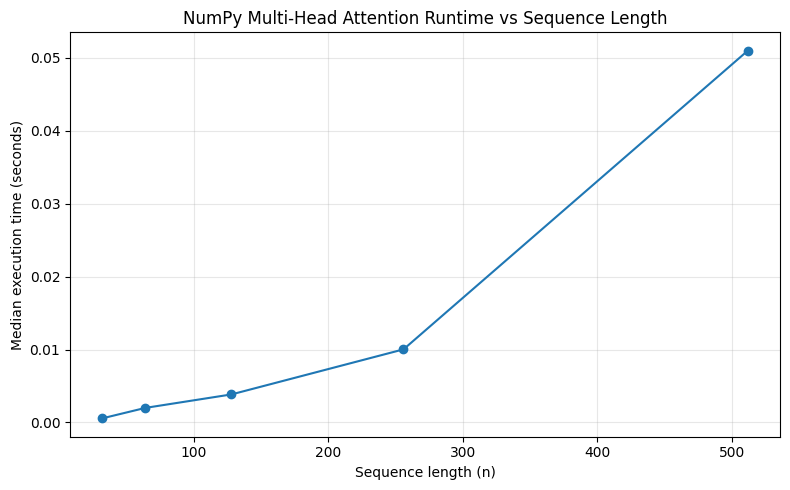

In [ ]:
lengths_plot = [r["sequence_length"] for r in benchmark_results10]
times_plot = [r["median_time_seconds"] for r in benchmark_results10]

plt.figure(figsize=(8, 5))
plt.plot(lengths_plot, times_plot, marker="o")
plt.xlabel("Sequence length (n)")
plt.ylabel("Median execution time (seconds)")
plt.title("NumPy Multi-Head Attention Runtime vs Sequence Length")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10.2 Complexity and design trade-offs

The attention score and attention-weight matrices contain `H × n²` elements, so their memory grows quadratically with sequence length. The total score and weighted-value arithmetic is approximately proportional to `n² × d_model`. Increasing the number of heads changes the partitioning of the model dimension; with fixed `d_model`, the leading total attention arithmetic remains of the same order.

A causal mask changes which positions are allowed to interact, but a basic dense NumPy implementation still computes dense matrix operations and stores dense arrays. Therefore, masking alone does not guarantee lower arithmetic cost or memory use. Actual savings require an implementation that skips masked operations or uses an efficient sparse/structured attention algorithm.

# Final validation and assignment submission checklist

Run this final cell after executing all previous sections. It checks that the key experiments and shape requirements were completed.

In [ ]:
checks = {
    "Q1 positional encoding shape (20, 16)": PE.shape == (20, 16),
    "Q1 manual 3x4 verification": np.allclose(PE_manual_case, expected),
    "Q2 attention rows sum to 1": np.allclose(returned_weights2.sum(axis=1), 1.0),
    "Q3 projection output has expected shape": out3.shape == (2, 2),
    "Q4 future-token weights are zero": np.all(weights4[future_positions] == 0.0),
    "Q5 cross-attention shape is (1, 3)": w5_fn.shape == (1, 3),
    "Q6 multi-head output shape is (5, 8)": out6.shape == (5, 8),
    "Q7 stable softmax is finite": np.all(np.isfinite(stable_softmax(test_logits))),
    "Q8 encoder output shape is (5, 8)": Y8.shape == (5, 8),
    "Q9 decoder output shape is (3, 8)": decoder_output9.shape == (3, 8),
    "Q10 benchmark includes five sequence lengths": len(benchmark_results10) == 5
}

for label, passed in checks.items():
    print(("PASS" if passed else "FAIL") + " — " + label)

print(f"\n{sum(checks.values())}/{len(checks)} checks passed.")
assert all(checks.values())

PASS — Q1 positional encoding shape (20, 16)
PASS — Q1 manual 3x4 verification
PASS — Q2 attention rows sum to 1
PASS — Q3 projection output has expected shape
PASS — Q4 future-token weights are zero
PASS — Q5 cross-attention shape is (1, 3)
PASS — Q6 multi-head output shape is (5, 8)
PASS — Q7 stable softmax is finite
PASS — Q8 encoder output shape is (5, 8)
PASS — Q9 decoder output shape is (3, 8)
PASS — Q10 benchmark includes five sequence lengths

11/11 checks passed.


## Submission reminders

1. Save this notebook as `.ipynb` and run every code cell.
2. Inspect the printed matrices, tensor shapes, verification results, and plots.
3. Prepare the required scanned handwritten PDF separately. Include derivations, manual calculations, intermediate matrices, and architecture diagrams for the questions.
4. Review the assignment's exact deliverables and upload the notebook and handwritten notes to the required GitHub/submission location.
5. Be prepared to explain the implementation and its dimensions during the class presentation.

**Note:** This notebook implements the requested mathematical components and experiments. It is an educational NumPy implementation, not a trained language model.